# RAG Agent (검색 증강 생성 에이전트)

**RAG (Retrieval-Augmented Generation)** 는 외부 지식 소스에서 정보를 검색하여 LLM의 응답을 향상시키는 기술입니다.

RAG 에이전트는 검색 도구를 사용하여 관련 문서를 찾고, 이를 컨텍스트로 활용하여 답변을 생성합니다.

**참고**: [LangChain 공식 문서 - RAG Agent](https://docs.langchain.com/oss/python/langchain/rag)

## RAG 워크플로우

1. **인덱싱 (Indexing)**: 문서를 로드, 분할, 임베딩하여 벡터 스토어에 저장
2. **검색 및 생성 (Retrieval & Generation)**: 사용자 질문에 대해 관련 문서를 검색하고 답변 생성

## RAG 패턴 이해

RAG는 두 가지 주요 접근 방식이 있습니다.
이 노트북에서는 **에이전트 기반 RAG를 중심으로** 다루고, 체인 기반 RAG는 마지막에 참고로 비교합니다.

### 패턴 1: 에이전트 기반 RAG (Agentic RAG)

에이전트가 필요할 때만 검색 도구를 호출합니다.
- 장점: 유연성, 필요할 때만 검색
- 단점: 여러 번의 모델 호출로 인한 지연 시간

### 패턴 2: 체인 기반 RAG (Chain-based RAG)

항상 검색을 먼저 실행하고 결과를 컨텍스트로 제공합니다.
- 장점: 단일 모델 호출로 빠름
- 단점: 항상 검색하므로 유연성 낮음

## 학습 내용
- RAG Agent를 위한 벡터 스토어 구축 (로드 → 분할 → 임베딩 → 저장)
- 검색 도구 정의 및 에이전트 통합
- 에이전트 기반 RAG vs 체인 기반 RAG

In [1]:
from dotenv import load_dotenv
import os

load_dotenv()

True

In [2]:
from langchain.chat_models import init_chat_model
from langchain_openai import OpenAIEmbeddings
from langchain_core.vectorstores import InMemoryVectorStore

# 모델 및 임베딩 초기화
model = init_chat_model(
    os.environ["OPENAI_MODEL"],
    model_provider="openai",
    use_responses_api=True,        # Responses API 사용 (Chat Completions에서는 추론 모델의 도구 호출 불가)
    reasoning={"effort": "low"},   # 추론 강도 낮춤 → 실습 속도·비용 절감
)
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

# 벡터 스토어 생성 (간단한 실습용 인메모리 방식)
# 영구 저장이 필요하면 Chroma 등으로 교체 가능:
#   from langchain_chroma import Chroma
#   vector_store = Chroma(collection_name="nike_10k", embedding_function=embeddings,
#                         persist_directory="./chroma_langchain_db")
vector_store = InMemoryVectorStore(embeddings)

## 1. 인덱싱: RAG Agent를 위한 벡터 스토어 구축

에이전트가 검색할 지식 베이스를 만드는 단계입니다.
PDF 문서를 로드하고, 검색에 적합한 크기로 분할한 뒤, 임베딩하여 벡터 스토어에 저장합니다.

LangChain은 다양한 문서 소스를 지원합니다: PDF, 웹페이지, 데이터베이스, API 등.
(웹페이지는 `WebBaseLoader`, PDF는 `PyPDFLoader` 사용)

In [ ]:
# pip install pypdf

### 1.1 문서 로드

In [3]:
from langchain_community.document_loaders import PyPDFLoader

# PDF 파일 로드 (나이키 10-K 연례 보고서, 한국어 번역본)
file_path = "./example_data/nke-10k-2023_korean.pdf"
loader = PyPDFLoader(file_path)
docs = loader.load()

print(f"로드된 페이지 수: {len(docs)}")
print(f"\n첫 페이지 미리보기:\n{docs[0].page_content[:200]}...")

로드된 페이지 수: 103

첫 페이지 미리보기:
목차 
미국 
증권거래위원회(SEC) 워싱턴 D.C. 20549 
양식 10-K 
(마크 1) 
☑ 2023 년 5 월 31 일에 종료되는 회계 연도에 대한 1934 년 증권거래법 섹션 13 또는 15(D)에 따른 연례 보고서 
또는 
☐ 1934 년 증권거래법(SECURITIES EXCHANGE ACT OF 1934)의 섹션 13 또는 15(D)에 따른 ...


### 1.2 텍스트 분할 (Text Splitting)

페이지 단위는 검색에 너무 큽니다. 더 작은 청크로 분할하여 정확한 검색이 가능하도록 합니다.

**중요 설정:**
- `chunk_size`: 각 청크의 최대 크기
- `chunk_overlap`: 청크 간 중첩 (문맥 유지)

In [4]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

# 텍스트 분할기 설정
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,      # 각 청크 최대 1000자
    chunk_overlap=200,    # 청크 간 200자 중첩
    add_start_index=True  # 원본 문서 내 시작 위치 저장
)

# 문서 분할
all_splits = text_splitter.split_documents(docs)

print(f"분할된 청크 수: {len(all_splits)}")

분할된 청크 수: 283


### 1.3 임베딩 후 벡터 스토어에 저장

텍스트를 숫자 벡터로 변환하여 저장합니다. 의미가 유사한 텍스트는 벡터 공간에서 가까운 위치에 있으므로,
질문과 의미가 비슷한 청크를 유사도 기반으로 찾을 수 있습니다.

In [5]:
# 문서를 벡터 스토어에 추가 (내부적으로 임베딩 수행)
document_ids = vector_store.add_documents(documents=all_splits)
print(f"저장된 문서 ID 수: {len(document_ids)}")

저장된 문서 ID 수: 283


### 1.4 검색 동작 확인

에이전트에 연결하기 전에 벡터 스토어가 관련 문서를 잘 찾는지 확인합니다.

In [6]:
# 유사도 검색 테스트
query = "나이키는 미국에 몇 개의 유통 센터를 가지고 있나요?"
results = vector_store.similarity_search(query, k=2)

print(f"검색 쿼리: {query}\n")
for i, doc in enumerate(results, 1):
    print(f"[결과 {i}] 페이지: {doc.metadata.get('page', 'N/A')}")
    print(f"{doc.page_content[:200]}...\n")

검색 쿼리: 나이키는 미국에 몇 개의 유통 센터를 가지고 있나요?

[결과 1] 페이지: 4
Consumer) 사업부는 미국 내 다음과 같은 수의 소매점을 통해 제품을 판매합니다. 
미국 소매점 수 
NIKE 브랜드 팩토리 스토어 213  
NIKE 브랜드 인라인 매장(사원 전용 매장 포함) 74  
컨버스 점포(팩토리 점포 포함) 82  
합계 369  
미국에는 NIKE 가 8 개의 주요 유통 센터를 보유하고 있습니다. 항목 2 를 참조하십시오...

[결과 2] 페이지: 21
애널리스트의 추정치는 종종 우리의 추정치 또는 기대와 다릅니다. 당사의 영업 실적이 공개 시장 분석가 및 투자자의 추정치 또는 기대치를 밑돌면 주가가 하락할 수 
있습니다. 과거에는 증권 시장 가격이 하락한 후 NIKE 및 기타 회사를 상대로 증권 집단 소송이 제기되었습니다. 어떤 이유로든 주가가 변동하는 경우 향후 이러한 유형의 
소송에 연루될 수 있습니...



## 2. 에이전트 기반 RAG (Agentic RAG)

벡터 스토어 검색을 **도구(tool)** 로 감싸서 에이전트에 제공합니다.
에이전트는 질문에 답하기 위해 필요하다고 판단할 때 검색 도구를 호출합니다.

### 2.1 검색 도구 생성

`response_format="content_and_artifact"` 를 사용하면 LLM에게 전달할 문자열(content)과
원본 문서 객체(artifact)를 함께 반환할 수 있습니다.

In [8]:
from langchain.tools import tool

@tool(response_format="content_and_artifact")
def retrieve_context(query: str):
    """질문에 답하기 위해 관련 정보를 검색합니다.
    
    이 도구는 벡터 스토어에서 질문과 관련된 문서를 검색합니다.
    검색된 문서는 답변 생성에 사용됩니다.
    
    Args:
        query: 검색할 질문 또는 키워드
    """
    # 벡터 스토어에서 유사한 문서 검색
    retrieved_docs = vector_store.similarity_search(query, k=2)
    
    # 검색된 문서를 문자열로 직렬화
    serialized = "\n\n".join(
        f"출처: {doc.metadata.get('source', 'N/A')} (페이지 {doc.metadata.get('page', 'N/A')})\n내용: {doc.page_content}"
        for doc in retrieved_docs
    )
    
    # 문자열과 문서 객체를 함께 반환
    return serialized, retrieved_docs

# 도구 테스트
test_result = retrieve_context.invoke("나이키의 유통 센터")
print(test_result[:300] + "...")

출처: ./example_data/nke-10k-2023_korean.pdf (페이지 50)
내용: 목차 
2023 양식 10-K 54 
 
나이키, INC. 
연결손익계산서 
연말 5 월 31 일, 
 
(단위: 백만 단위, 주당 데이터 제외) 2023 2022 2021 
수익 $ 51,217  $ 46,710 $ 44,538  
매출 원가  28,925   25,231  24,576  
매출 총이익  22,292   21,479  19,962  
수요 창출 비용  4,060   3,850  3,114  
영업간접비  12,317...


### 2.2 RAG 에이전트 생성

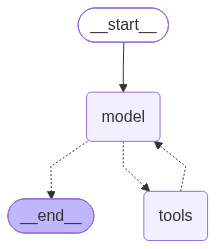

In [9]:
from langchain.agents import create_agent

# 시스템 프롬프트 설정
system_prompt = (
    "당신은 나이키 연례 보고서(10-K)에서 관련 문맥(context)을 검색하는 도구에 접근할 수 있습니다. "
    "사용자의 질문에 답하기 위해 먼저 retrieve_context 도구를 사용하여 관련 정보를 검색한 후, "
    "검색된 정보를 바탕으로 정확하고 유용한 답변을 제공하세요."
)

# 에이전트 생성
agent = create_agent(
    model,
    tools=[retrieve_context],
    system_prompt=system_prompt
)

agent

### 2.3 에이전트 실행

스트리밍 방식으로 실행하면 에이전트의 동작 과정(도구 호출 → 검색 결과 → 최종 답변)을 단계별로 볼 수 있습니다.

In [10]:
# 질문에 대한 답변 생성
query = "나이키는 미국에 몇 개의 유통 센터를 가지고 있나요?"

print(f"질문: {query}\n")
print("=" * 80)

# 스트리밍 방식으로 실행
for event in agent.stream(
    {"messages": [{"role": "user", "content": query}]},
    stream_mode="values",
):
    event["messages"][-1].pretty_print()

질문: 나이키는 미국에 몇 개의 유통 센터를 가지고 있나요?

================================ Human Message =================================

나이키는 미국에 몇 개의 유통 센터를 가지고 있나요?
================================== Ai Message ==================================

[{'arguments': '{"query":"Nike number of distribution centers in the United States annual report 10-K"}', 'call_id': 'call_FHSiyuw4lE655ciFLCEkDQih', 'name': 'retrieve_context', 'type': 'function_call', 'id': 'fc_0cf15347750eebc0006ae6f9a9db3c87d0a591144117888804', 'status': 'completed'}]
Tool Calls:
  retrieve_context (call_FHSiyuw4lE655ciFLCEkDQih)
 Call ID: call_FHSiyuw4lE655ciFLCEkDQih
  Args:
    query: Nike number of distribution centers in the United States annual report 10-K
================================= Tool Message =================================
Name: retrieve_context

출처: ./example_data/nke-10k-2023_korean.pdf (페이지 4)
내용: Consumer) 사업부는 미국 내 다음과 같은 수의 소매점을 통해 제품을 판매합니다. 
미국 소매점 수 
NIKE 브랜드 팩토리 스토어 213  
NIKE 브랜드 인라인 매장(사원 전용 매장 포함) 74  
컨버스 점포

### 2.4 여러 질문 테스트

In [11]:
queries = [
    "2023년 나이키의 매출은 얼마였나요?",
    "나이키의 주요 시장은 어디인가요?"
]

for query in queries:
    print(f"\n{'='*80}")
    print(f"질문: {query}")
    print("="*80)
    
    result = agent.invoke({
        "messages": [{"role": "user", "content": query}]
    })
    
    print("\n답변:")
    print(result["messages"][-1].text)


질문: 2023년 나이키의 매출은 얼마였나요?

답변:
NIKE, Inc.의 2023 회계연도 매출은 **512억 달러**였습니다. 이는 2023년 5월 31일 종료된 회계연도 기준이며, 전년 대비 10% 증가했습니다.

질문: 나이키의 주요 시장은 어디인가요?

답변:
나이키는 주요 시장을 지역별로 운영하며, 2023 회계연도 기준으로는 다음과 같습니다.

- 북아메리카
- 유럽·중동·아프리카(EMEA)
- 중화권
- 아시아 태평양·라틴 아메리카(APLA)

이 중 북아메리카가 가장 큰 시장으로, 2023 회계연도 매출은 약 216억 달러였습니다. EMEA는 약 134억 달러, 중화권은 약 72억 달러, APLA는 약 64억 달러였습니다.


## 3. 참고 : 체인 기반 RAG (Chain-based RAG) 

에이전트가 판단하지 않고 **항상 검색을 먼저 실행**한 뒤 결과를 컨텍스트로 제공하는 방식입니다.
단일 모델 호출이므로 빠르지만, 검색이 불필요한 질문에도 항상 검색을 수행합니다.

In [12]:
# 체인 기반 RAG 예제
from langchain_core.messages import HumanMessage

def chain_based_rag(query: str):
    """체인 기반 RAG: 항상 검색 후 답변 생성"""
    # 1. 검색
    retrieved_docs = vector_store.similarity_search(query, k=2)
    context = "\n\n".join(doc.page_content for doc in retrieved_docs)
    
    # 2. 컨텍스트와 함께 답변 생성
    messages = [
        HumanMessage(content=f"""다음 컨텍스트를 참고하여 질문에 답변하세요:

컨텍스트:
{context}

질문: {query}

답변:""")
    ]
    
    response = model.invoke(messages)
    return response.text

# 체인 기반 RAG 테스트
query = "나이키의 매출 총이익은 얼마인가요?"
print(f"질문: {query}\n")
answer = chain_based_rag(query)
print(f"답변: {answer}")

질문: 나이키의 매출 총이익은 얼마인가요?

답변: 나이키의 2023 회계연도 매출 총이익은 **222억 9,200만 달러**입니다.


### 실습 문제

본문에서 배운 **인덱싱 → 검색 도구 → RAG 에이전트** 전체 흐름을 새로운 문서에 적용해 **블로그 QA 에이전트**를 완성하세요.

1. **인덱싱**:
   `WebBaseLoader`로 웹 문서 https://botpress.com/ko/blog/llm-agents 를 로드하고,
   `RecursiveCharacterTextSplitter`(chunk_size=1000, chunk_overlap=200)로 분할한 뒤,
   본문의 나이키 벡터 스토어와는 **별도의 새 `InMemoryVectorStore`** 에 저장하세요.

2. **검색 도구**:
   `@tool(response_format="content_and_artifact")` 데코레이터로
   `retrieve_blog_context(query)` 도구를 정의하세요.
   벡터 스토어에서 `k=3`으로 검색하고, 출처(source)를 포함한 문자열로 직렬화해 반환하세요.

3. **RAG 에이전트**:
   `create_agent`로 에이전트를 생성하세요. system prompt에
   **"반드시 검색된 정보에 근거해서 답변하고, 검색 결과에 없는 내용은 모른다고 답하세요"** 지침을 포함하세요.

4. **테스트**: 아래 질문들로 에이전트를 실행하고, 도구 호출 여부와 답변을 확인하세요.

### 테스트 입력 예시

* `"LLM 에이전트를 정의하는 4가지 특징은 무엇인가요?"`
  👉 retrieve_blog_context 도구 호출 → 블로그 내용에 근거한 답변

* `"나이키의 2023년 매출은 얼마였나요?"`
  👉 블로그에 없는 내용 → 에이전트가 모른다고 답하는지(환각 방지) 확인